# MyFinSight 분석 결과 한눈에 보기

`output/13_results.json` 하나만 읽어서, 파이프라인이 **무엇을 받아(요청) → 어떻게 이해하고(의도) → 어떤 종목을 골라(선정) → 어떻게 나누고(구성) → 과거에 적용하면 어땠고(백테스트) → 기준을 통과했는지(검증)** 를 순서대로 보여줍니다.
각 절의 표와 그래프는 모두 같은 결과 파일의 숫자입니다.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.family"] = "AppleGothic"      # macOS 한글 폰트 (다른 OS: 'Malgun Gothic' / 'NanumGothic')
mpl.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)

import os
RESULTS = Path(os.environ.get("MYFINSIGHT_RESULTS", "../output/13_results.json"))   # 기본: notebooks/ 기준 상대 경로
R = json.loads(RESULTS.read_text(encoding="utf-8"))
pct = lambda x: "–" if x is None else f"{x*100:+.2f}%"
pct1 = lambda x: "–" if x is None else f"{x*100:.1f}%"
usd = lambda x: "–" if x is None else f"{x:,.2f} USD"
krw = lambda x: "–" if x is None else f"{x:,.0f}원"
print("request_id:", R["request_id"], "| generated:", R["generated_at"], "| pipeline:", R["pipeline_version"])

request_id: req_2026-10-10_brd1 | generated: 2026-10-10T11:48:14 | pipeline: mockup-2026.10


## 1. 요청 — 사용자가 입력한 것

In [2]:
q, d, c, h, r = R["request"], R["request"]["derived"], R["request"]["capital"], R["request"]["horizon"], R["request"]["risk"]
rows = [("투자금", f"{c['initial_amount']:,.0f}원 → {usd(d['initial_amount_usd'])}  (환율 {R['money_krw']['direction']}, {d['fx_date']})"),
        ("월 적립", f"{c['monthly_contribution']:,.0f}원 (매월 {c['contribution_day']}일) → {usd(d['monthly_contribution_usd'])}"),
        ("투자기간", f"{h['target_years']}년, 시작 희망일 {h['start_date']}"),
        ("투자성향", f"{r['risk_tolerance']} · 손실 감내 수준 {r['max_drawdown_tolerance']:.0%} · 손실 시 {r['loss_reaction']}"),
        ("목표 수익률 / 비교지수", f"연 {r['target_annual_return']:.0%} / {r['benchmark']}"),
        ("전략 템플릿 / 기준 비중", f"{q['strategy_preference']['template']} / {q['strategy_preference']['baseline_weighting']}"),
        ("투자 아이디어", q["natural_language"]["idea"])]
pd.DataFrame(rows, columns=["항목", "내용"]).set_index("항목")

,내용
항목,
투자금,"100,000,000원 → 74,625.75 USD (환율 1 USD = 1,340.02 KRW, 2026-10-09)"
월 적립,0원 (매월 25일) → 0.00 USD
투자기간,"10.0년, 시작 희망일 2026-10-09"
투자성향,conservative · 손실 감내 수준 20% · 손실 시 hold
목표 수익률 / 비교지수,연 6% / SPY
전략 템플릿 / 기준 비중,low_volatility / min_variance
투자 아이디어,특정 산업을 고르고 싶지는 않아요. 미국을 대표하는 크고 탄탄한 회사들에 골고루 나눠 담아서 10년 넘게 묻어 두고 싶습니다. 주가가 출...


## 2. 의도 해석 — 분석 모델이 아이디어를 어떻게 이해했나

In [3]:
I = R["intent"]
print(I["interpretation"]["summary_ko"]); print()
themes = pd.DataFrame([{"테마": t["label_ko"], "설명": t["description_ko"], "GICS 코드": ", ".join(t["gics_codes"]), "키워드": ", ".join(t["keywords"][:6])} for t in I["interpretation"]["themes"]])
display(themes.set_index("테마"))
cons = q["constraints"]
display(pd.DataFrame([("종목 수", f"목표 {cons['num_holdings']['target']} (허용 {cons['num_holdings']['min']}~{cons['num_holdings']['max']})"), ("종목당 상한", f"{cons['max_weight_per_stock']:.0%}"), ("섹터당 상한", f"{cons['max_weight_per_sector']:.0%}"),
                      ("리밸런싱", d["rebalance_rule"]["description_ko"]), ("제외 테마", ", ".join(cons["exclude_themes"]) or "없음"),
                      ("변동성 선호 / 허용 MDD", f"{I['risk_params']['volatility_preference']} / {I['risk_params']['effective_max_drawdown']:.0%}"), ("해석 메모", I["risk_params"]["notes_ko"])], columns=["항목", "값"]).set_index("항목"))
if I["interpretation"]["conflicts"]:
    display(pd.DataFrame(I["interpretation"]["conflicts"]).rename(columns={"field": "항목", "issue_ko": "확인한 점", "resolution_ko": "처리"}))

특정 산업에 집중하기보다 미국의 대형·탄탄한 기업을 여러 업종에 분산하고, 변동성이 낮은 종목을 장기 보유하려는 의도입니다. 담배·도박·무기 관련 기업은 제외합니다.



,설명,GICS 코드,키워드
테마,,,
미국 대형 우량주 분산,"특정 산업에 한정하지 않고, 미국 시장에서 규모가 크고 사업 기반과 재무 건전성이 탄탄한 기업을 포괄합니다. 한 업종에 집중하지 않도록 ...","10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60","large cap, blue chip, market leader, strong balance sheet, established busin..."


,값
항목,
종목 수,목표 20 (허용 15~25)
종목당 상한,8%
섹터당 상한,30%
리밸런싱,1×1년마다 리밸런싱
제외 테마,"tobacco, gambling, weapons"
변동성 선호 / 허용 MDD,low / 20%
해석 메모,손실 발생 시 hold로 응답했으므로 최대 낙폭을 추가로 낮추지 않습니다. 투자 경험은 beginner이며 none이 아니므로 추가 보정...


,항목,확인한 점,처리
0,horizon.target_years / natural_language.idea,구조화된 목표 보유 기간은 10년이지만 자연어 아이디어는 10년을 넘겨 보유하고 싶다는 뜻을 담고 있습니다.,명시된 horizon.target_years 값인 10년을 적용합니다.


## 3. 종목 선정 — 깔때기와 선정 표

유니버스 → 테마 관련 후보(GICS·키워드) → 테마 해당 판정(분석 모델) → 선정 지표 순위 → 섹터 상한 → 최종. 백테스트는 시작일 당시 정보로 같은 규칙을 다시 적용하므로 목록이 다를 수 있습니다.

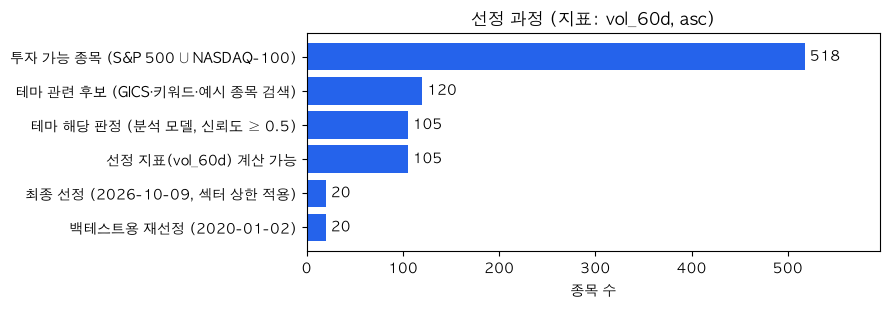

,회사,섹터,테마,신뢰도,순위(2020-01-02),지표(백테스트),순위(2026-10-09),지표(2026),테마 판정 사유
티커,,,,,,,,,
PEP,PepsiCo,Consumer Staples,diversified_us_blue_chip,0.95,1.0,+8.89%,8.0,+18.92%,글로벌 음료·스낵 브랜드와 안정적인 소비재 사업 기반을 보유
BRK-B,Berkshire Hathaway,Financials,diversified_us_blue_chip,0.99,2.0,+9.94%,1.0,+13.54%,보험·철도·유틸리티 등 여러 업종에 걸친 미국 대형 지주사
WMT,Walmart,Consumer Staples,diversified_us_blue_chip,0.95,3.0,+9.97%,NaN,+nan%,세계 최대급 유통망과 필수소비재 판매 기반을 보유한 미국 기업
VZ,Verizon,Communication Services,diversified_us_blue_chip,0.85,4.0,+10.67%,NaN,+nan%,미국 전역의 유무선 통신망과 서비스를 제공하는 대형 사업자
COST,Costco,Consumer Staples,diversified_us_blue_chip,0.98,5.0,+11.03%,4.0,+17.00%,회원제 창고형 매장을 세계적으로 운영하는 대형 유통기업
KO,Coca-Cola Company (The),Consumer Staples,diversified_us_blue_chip,0.97,6.0,+11.56%,10.0,+19.30%,세계적 음료 브랜드와 광범위한 유통망을 보유한 대형 소비재 기업
AMGN,Amgen,Health Care,diversified_us_blue_chip,0.95,7.0,+12.63%,NaN,+nan%,다양한 치료제를 보유한 대형 바이오제약 기업
ACN,Accenture,Information Technology,diversified_us_blue_chip,0.94,8.0,+13.18%,NaN,+nan%,글로벌 컨설팅·IT 서비스 사업을 갖춘 대형 기업
MSFT,Microsoft,Information Technology,diversified_us_blue_chip,0.98,9.0,+13.35%,NaN,+nan%,클라우드·소프트웨어·생산성 제품을 아우르는 초대형 글로벌 기업


백테스트 재선정에서 추가: ['ACN', 'AMGN', 'GOOG', 'GOOGL', 'MSFT', 'VZ', 'WFC', 'WMT'] | 빠짐: ['ABBV', 'BAC', 'JNJ', 'MA', 'MCD', 'PG', 'UNH', 'UNP']


,회사,제외 이유,지표값
티커,,,
TJX,TJX Companies,rank_beyond_n,0.226246
WFC,Wells Fargo,rank_beyond_n,0.231329
SCHW,Charles Schwab Corporation,rank_beyond_n,0.232051
CVX,Chevron Corporation,rank_beyond_n,0.232406
XOM,ExxonMobil,rank_beyond_n,0.237605
GILD,Gilead Sciences,rank_beyond_n,0.239567
C,Citigroup,rank_beyond_n,0.243987
MS,Morgan Stanley,rank_beyond_n,0.245370


In [4]:
S = R["selection"]
f = pd.DataFrame(S["funnel"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(f["label_ko"][::-1], f["count"][::-1], color="#2563eb")
for i, v in enumerate(f["count"][::-1]): ax.text(v + 5, i, str(v), va="center")
ax.set_xlabel("종목 수"); ax.set_title(f"선정 과정 (지표: {S['metric']}, {S['direction']})"); ax.set_xlim(0, f["count"].max() * 1.15)
plt.tight_layout(); plt.show()

t = pd.DataFrame(S["table"])
view = t[["ticker", "name", "sector", "themes", "theme_confidence", "rank_backtest", "metric_backtest", "rank_2026", "metric_2026", "theme_reason_ko"]].copy()
view["themes"] = view["themes"].str.join(", "); view["metric_backtest"] = view["metric_backtest"].map(pct); view["metric_2026"] = view["metric_2026"].map(pct)
view.columns = ["티커", "회사", "섹터", "테마", "신뢰도", f"순위({S['backtest_as_of']['as_of']})", "지표(백테스트)", f"순위({S['as_of_2026']['as_of']})", "지표(2026)", "테마 판정 사유"]
display(view.set_index("티커"))
diff = S["backtest_as_of"]["diff_vs_original"]
print("백테스트 재선정에서 추가:", diff["added"], "| 빠짐:", diff["removed"])
display(pd.DataFrame(S["as_of_2026"]["rejected_examples"]).rename(columns={"ticker": "티커", "name": "회사", "reason": "제외 이유", "metric_value": "지표값"}).set_index("티커"))

## 4. 포트폴리오 구성 — 기준 비중, 규칙 4가지, 시나리오 5개

기준은 1/N 동일비중이고, 종목·섹터 상한으로 재배분합니다. Black-Litterman 타겟은 기준 비중에 시나리오 뷰를 종목당 최대 `max_tilt` 만큼만 반영한 것입니다.

,섹터,1/N,최종 비중
PEP,Consumer Staples,5.0%,8.0%
BRK-B,Financials,5.0%,2.6%
WMT,Consumer Staples,5.0%,8.0%
VZ,Communication Services,5.0%,8.0%
COST,Consumer Staples,5.0%,6.0%
KO,Consumer Staples,5.0%,8.0%
AMGN,Health Care,5.0%,4.2%
ACN,Information Technology,5.0%,1.6%
MSFT,Information Technology,5.0%,1.0%
PFE,Health Care,5.0%,8.0%


적용된 제약: ['optimizer_constraints'] | 섹터 비중: {'Consumer Staples': 0.3, 'Financials': 0.202, 'Communication Services': 0.1, 'Health Care': 0.212, 'Information Technology': 0.026, 'Utilities': 0.08, 'Materials': 0.08}


,설명,예상 변동성,유효 종목 수,최대 비중
규칙,,,,
동일비중,모든 종목에 같은 비중 1/N,11.9%,20.0,5.0%
시가총액비중,시가총액에 비례한 비중 (지수 방식),12.5%,16.8,8.0%
역변동성비중,변동성이 낮은 종목에 더 큰 비중 (1/σ 정규화),11.5%,19.6,6.5%
최소분산,포트폴리오 분산을 최소화하는 비중 (제약 포함 최적화),10.6%,14.6,8.0%


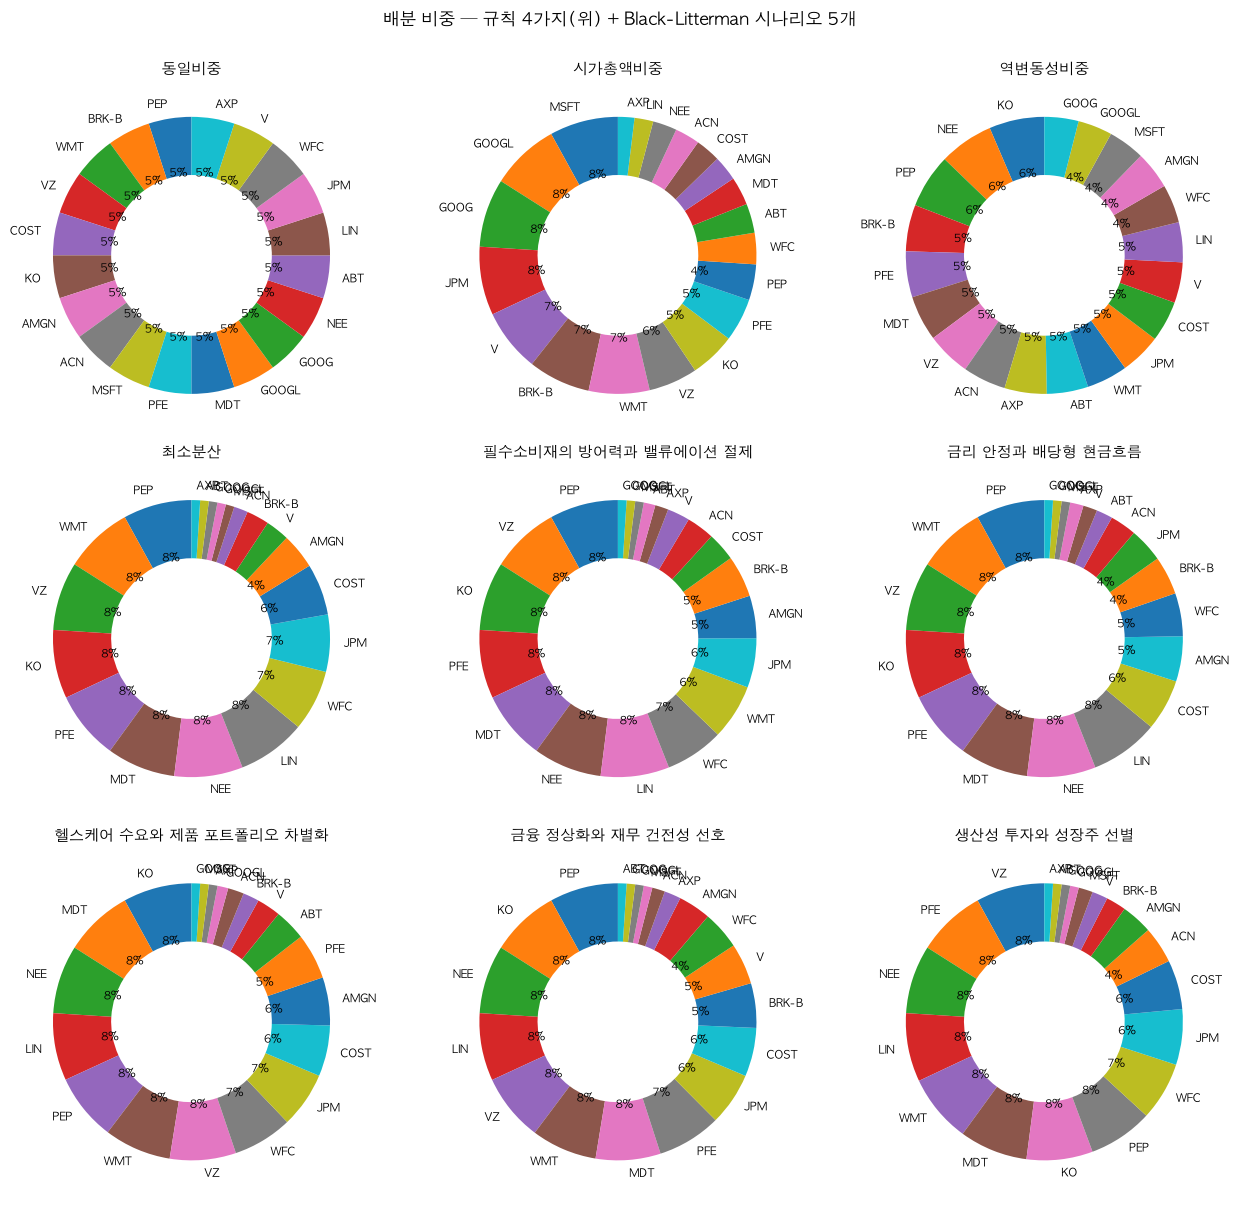

In [5]:
P = R["portfolio"]; base = next(p for p in P["baselines"]["portfolios"] if p["id"] == P["baselines"]["chosen_baseline"])
n = len(base["weights"]); sec = {x["ticker"]: x["sector"] for x in S["table"]}
bt_ = pd.DataFrame({"섹터": {t: sec.get(t, "") for t in base["weights"]}, "1/N": {t: 1/n for t in base["weights"]}, "최종 비중": base["weights"]})
display(bt_.style.format({"1/N": "{:.1%}", "최종 비중": "{:.1%}"}))
print("적용된 제약:", base["constraints_applied"], "| 섹터 비중:", {k: round(v, 3) for k, v in base["sector_weights"].items()})

tmpl = pd.DataFrame([{"규칙": p["name_ko"], "설명": p["rule_ko"], "예상 변동성": p["ex_ante"]["vol"], "유효 종목 수": p["ex_ante"]["effective_n"], "최대 비중": max(p["weights"].values())} for p in P["baselines"]["portfolios"]])
display(tmpl.set_index("규칙").style.format({"예상 변동성": "{:.1%}", "최대 비중": "{:.1%}", "유효 종목 수": "{:.1f}"}))

ports = P["baselines"]["portfolios"] + P["targets"]["portfolios"]
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, p in zip(axes.flat, ports):
    items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
    ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
    ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=11)
plt.suptitle("배분 비중 — 규칙 4가지(위) + Black-Litterman 시나리오 5개", y=1.0); plt.tight_layout(); plt.show()

,관점,뷰,최대 변화,예상 수익,예상 변동성
시나리오,,,,,
필수소비재의 방어력과 밸류에이션 절제,경기 둔화 우려가 커지면 브랜드와 반복 구매에 기반한 필수소비재가 포트폴리오의 변동성을 완충할 수 있습니다. 최근 강한 상승을 보인 대형 할인점보다는 가격 결정력과 안정적인 현금흐름을 중시합니다.,[절대] PEP +8%/년 (신뢰 0.24) / [절대] KO +8%/년 (신뢰 0.22) / [상대] PEP+KO > COST+WMT +6%/년 (신뢰 0.20) / [상대] KO+PEP > COST +5%/년 (신뢰 0.18),+2.7%,8.9%,10.9%
금리 안정과 배당형 현금흐름,"금리가 안정되면 배당과 예측 가능한 현금흐름을 제공하는 기업의 상대 매력이 유지될 수 있습니다. 다만 이미 큰 폭으로 오른 유틸리티는 기대수익을 보수적으로 보고, 통신과 방어적 소비재를 함께 두어 균형을 맞춥니다.",[절대] NEE +6%/년 (신뢰 0.18) / [절대] VZ +8%/년 (신뢰 0.20) / [상대] NEE > JPM+WFC +6%/년 (신뢰 0.17) / [상대] VZ+PEP > GOOGL+GOOG +5%/년 (신뢰 0.16),+2.7%,8.8%,10.9%
헬스케어 수요와 제품 포트폴리오 차별화,"고령화와 꾸준한 진단·치료 수요는 헬스케어 대형주의 중기 기반을 지지합니다. 제품군과 성장 동력이 다양한 기업을 선호하고, 제품 전환 부담이 있는 기업에는 상대적으로 신중한 관점을 둡니다.",[절대] ABT +12%/년 (신뢰 0.21) / [절대] AMGN +12%/년 (신뢰 0.20) / [상대] ABT+MDT > PFE +7%/년 (신뢰 0.19) / [상대] AMGN > PFE +5%/년 (신뢰 0.16),+2.7%,9.2%,10.9%
금융 정상화와 재무 건전성 선호,"미국 소비와 기업 활동이 급격히 약화되지 않는다면 우량 금융사의 다각화된 수익원이 안정성을 제공할 수 있습니다. 자본과 사업 기반이 탄탄한 Berkshire 및 JPMorgan을 선호하되, 결제 네트워크도 은행 대출 사이클과 다른 성장 동력으로 활용합니다.",[절대] BRK-B +12%/년 (신뢰 0.22) / [절대] JPM +11%/년 (신뢰 0.20) / [상대] BRK-B+JPM > WFC +6%/년 (신뢰 0.18) / [상대] V+AXP > WFC +7%/년 (신뢰 0.17),+2.7%,9.2%,10.9%
생산성 투자와 성장주 선별,클라우드·소프트웨어 수요와 기업의 디지털 전환은 대형 기술·서비스 기업의 성장을 뒷받침할 수 있습니다. 다만 높은 기대가 반영된 종목에 무조건 베팅하기보다 반복 매출과 산업용 소재의 기반을 함께 활용해 성장과 분산을 추구합니다.,[절대] MSFT +14%/년 (신뢰 0.20) / [절대] ACN +12%/년 (신뢰 0.19) / [상대] MSFT+ACN > GOOGL+GOOG +6%/년 (신뢰 0.16) / [상대] LIN > KO+PEP +5%/년 (신뢰 0.15),+2.7%,9.2%,10.9%


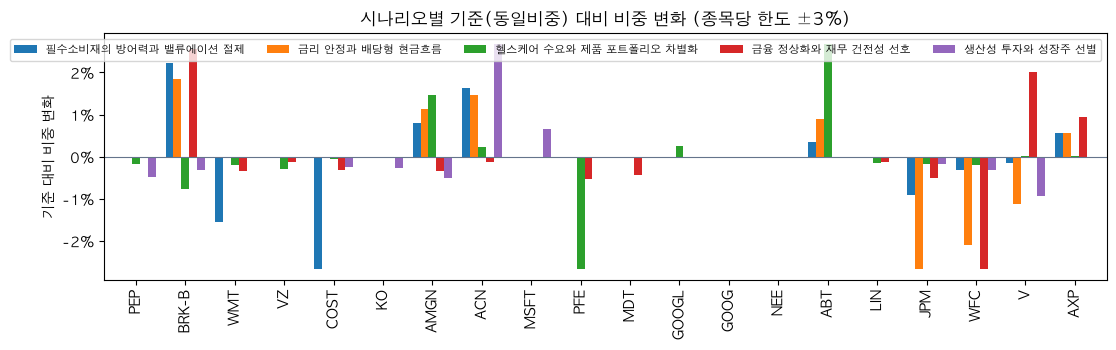

In [6]:
sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                    "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in P["targets"]["portfolios"]])
display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
dl = pd.DataFrame({p["title_ko"]: p["delta_vs_baseline"] for p in P["targets"]["portfolios"]})
ax = dl.plot.bar(figsize=(12, 3.6), width=0.8); ax.axhline(0, color="#64748b", lw=0.8); ax.set_ylabel("기준 대비 비중 변화"); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title(f"시나리오별 기준(동일비중) 대비 비중 변화 (종목당 한도 ±{P['targets']['parameters']['max_tilt_per_stock']:.0%})"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 5. 백테스트 — 같은 기간·같은 적립으로 9개 포트폴리오와 비교지수를 돌린 결과

In [7]:
BT = R["backtest"]; rec = R["validation"].get("recommended"); chosen = rec["id"] if rec else P["targets"]["baseline"]["id"]
label = lambda p: (f"시나리오: {p['title_ko']}" if p.get("title_ko") else p["name_ko"])
E = BT["engine"]; print(f"기간 {BT['period']['start']}~{BT['period']['end']} ({BT['period']['trading_days']}거래일) · 적립 {E['n_contributions']}회 × {E['contribution_usd']:.0f} USD · 거래비용 {E['commission_bps']}bp · 무위험 {E['risk_free_rate']:.0%} · {E['prices']}")
print("중심 포트폴리오:", chosen, "(추천)" if rec else "(추천 없음 → 기준 포트폴리오)")
rows = []
for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]:
    h, m = p["headline"], p["metrics"]
    rows.append({"포트폴리오": label(p), "종류": p["kind"], "누적수익": m["return"]["total_return"], "CAGR": h["cagr"], "변동성": m["risk"]["ann_vol"], "Sharpe": h["sharpe"], "최대낙폭": h["max_drawdown"],
                 "SPY 대비": h["excess_cagr"], "최종 평가금액": h["final_value_usd"], "투입 원금": p["money"]["net_invested_usd"], "XIRR": p["money"]["irr_annual"], "뷰 적중": h["view_hit_ratio"]})
comp = pd.DataFrame(rows).set_index("포트폴리오")
display(comp.style.format({"누적수익": "{:+.1%}", "CAGR": "{:+.1%}", "변동성": "{:.1%}", "Sharpe": "{:.2f}", "최대낙폭": "{:.1%}", "SPY 대비": "{:+.1%}", "최종 평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "XIRR": "{:+.1%}", "뷰 적중": "{:.0%}"}, na_rep="–").background_gradient(subset=["Sharpe"], cmap="Blues"))

기간 2020-01-02~2026-10-09 (1702거래일) · 적립 0회 × 0 USD · 거래비용 5bp · 무위험 4% · adj_close (dividends reinvested)
중심 포트폴리오: min_variance (추천 없음 → 기준 포트폴리오)


,종류,누적수익,CAGR,변동성,Sharpe,최대낙폭,SPY 대비,최종 평가금액,투입 원금,XIRR,뷰 적중
포트폴리오,,,,,,,,,,,
시나리오: 필수소비재의 방어력과 밸류에이션 절제,black_litterman,+93.1%,+10.2%,16.8%,0.37,-29.0%,-5.1%,"167,287","86,657",+10.2%,25%
시나리오: 금리 안정과 배당형 현금흐름,black_litterman,+96.0%,+10.5%,16.5%,0.39,-27.5%,-4.9%,"169,765","86,657",+10.4%,50%
시나리오: 헬스케어 수요와 제품 포트폴리오 차별화,black_litterman,+100.9%,+10.9%,16.7%,0.41,-28.3%,-4.5%,"173,984","86,657",+10.8%,75%
시나리오: 금융 정상화와 재무 건전성 선호,black_litterman,+100.3%,+10.8%,16.6%,0.41,-28.2%,-4.5%,"173,477","86,657",+10.8%,50%
시나리오: 생산성 투자와 성장주 선별,black_litterman,+98.0%,+10.6%,16.7%,0.40,-28.2%,-4.7%,"171,463","86,657",+10.6%,100%
동일비중,template,+130.8%,+13.2%,17.6%,0.52,-29.5%,-2.1%,"199,881","86,657",+13.1%,–
시가총액비중,template,+156.4%,+15.0%,17.8%,0.62,-28.9%,-0.4%,"222,080","86,657",+14.9%,–
역변동성비중,template,+120.3%,+12.4%,17.3%,0.49,-29.7%,-2.9%,"190,854","86,657",+12.4%,–
최소분산,template,+99.6%,+10.8%,16.7%,0.41,-28.2%,-4.6%,"172,919","86,657",+10.7%,–


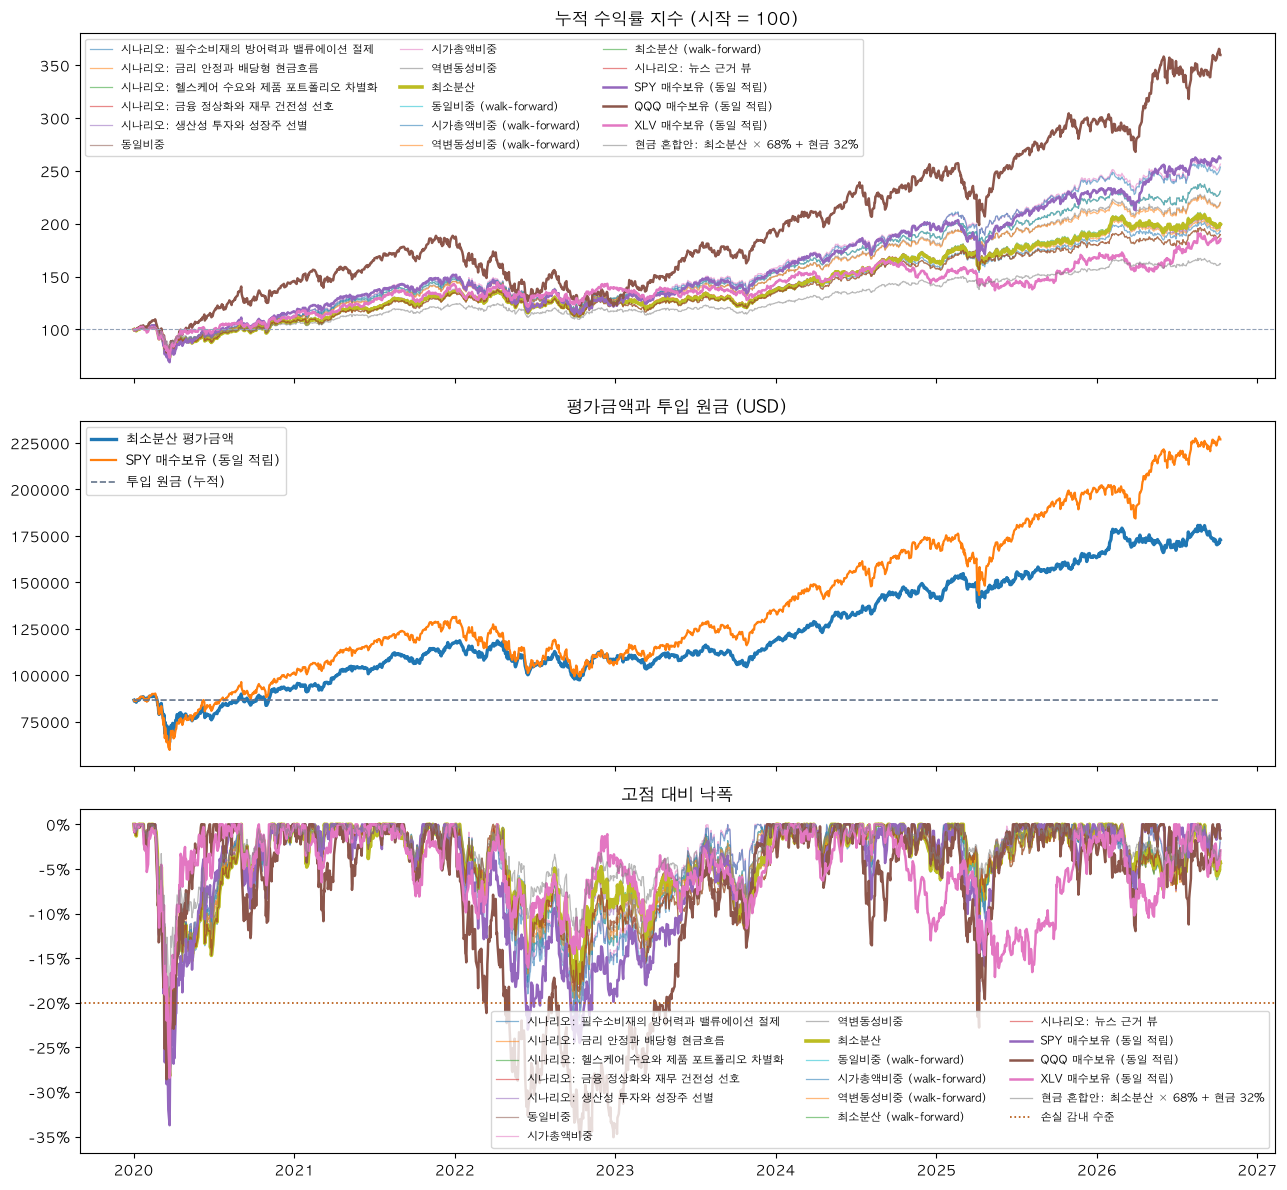

최소분산 최대낙폭 -28.2%: 고점 2020-02-14 → 저점 2020-03-23 → 회복 2020-09-02 (고점 아래 201일)


In [8]:
dates = pd.to_datetime(BT["series_dates"]); series = {p["id"]: p for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]}
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for pid, p in series.items():
    lw = 2.6 if pid == chosen else (1.8 if p["kind"] == "benchmark" else 0.9); alpha = 1 if (pid == chosen or p["kind"] == "benchmark") else 0.55
    axes[0].plot(dates, p["series"]["index"], lw=lw, alpha=alpha, label=label(p))
    axes[2].plot(dates, p["series"]["drawdown"], lw=lw, alpha=alpha, label=label(p))
axes[0].axhline(100, color="#94a3b8", ls="--", lw=0.8); axes[0].set_title("누적 수익률 지수 (시작 = 100)"); axes[0].legend(ncol=3, fontsize=8)
cp = series[chosen]; led = {l["date"]: l["amount_usd"] for l in cp["contribution_ledger"]}; inv, cum = [], cp["money"]["initial_usd"]
for ds in BT["series_dates"]: cum += led.get(ds, 0.0); inv.append(cum)
axes[1].plot(dates, cp["series"]["value_usd"], lw=2.4, label=f"{label(cp)} 평가금액"); axes[1].plot(dates, series[BT["benchmark"]["id"]]["series"]["value_usd"], lw=1.6, label="SPY 매수보유 (동일 적립)")
axes[1].plot(dates, inv, lw=1.2, ls="--", color="#64748b", label="투입 원금 (누적)"); axes[1].set_title("평가금액과 투입 원금 (USD)"); axes[1].legend(fontsize=9)
axes[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); axes[2].set_title("고점 대비 낙폭"); axes[2].axhline(-R["intent"]["risk_params"]["effective_max_drawdown"], color="#b45309", ls=":", lw=1.2, label="손실 감내 수준")
axes[2].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()
mdd = cp["metrics"]["risk"]["mdd"]; print(f"{label(cp)} 최대낙폭 {cp['headline']['max_drawdown']:.1%}: 고점 {mdd['peak_date']} → 저점 {mdd['trough_date']} → 회복 {mdd['recovery_date'] or '기간 내 미회복'} (고점 아래 {mdd['underwater_days']}일)")

,2020,2021,2022,2023,2024,2025,2026
최소분산,+8.7%,+24.9%,-7.8%,+9.1%,+19.9%,+15.2%,+5.9%
SPY 매수보유 (동일 적립),+17.2%,+28.7%,-18.2%,+26.2%,+24.9%,+17.7%,+14.4%


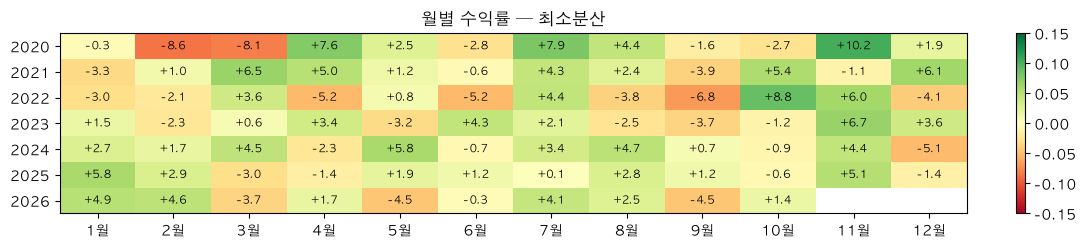

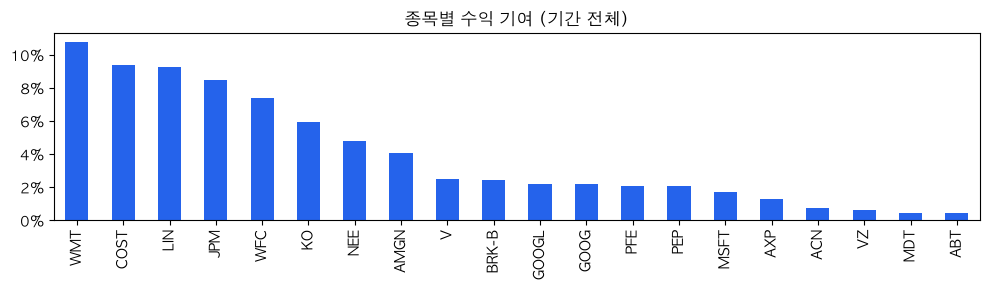

In [9]:
yr = pd.DataFrame({label(p): p["yearly_returns"] for p in [cp, series[BT["benchmark"]["id"]], series[P["targets"]["baseline"]["id"]]]}).T
display(yr.style.format("{:+.1%}", na_rep="–").set_caption("연도별 수익률 (첫해·마지막 해는 부분 기간)"))
mr = pd.DataFrame(cp["monthly_returns"]).pivot(index="year", columns="month", values="return")
fig, ax = plt.subplots(figsize=(11, 2.6)); im = ax.imshow(mr.values, cmap="RdYlGn", vmin=-0.15, vmax=0.15, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels([f"{m}월" for m in range(1, 13)]); ax.set_yticks(range(len(mr.index))); ax.set_yticklabels(mr.index)
for i in range(mr.shape[0]):
    for j in range(mr.shape[1]):
        v = mr.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v*100:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title(f"월별 수익률 — {label(cp)}"); plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()
contrib = pd.Series(cp["ticker_contribution"]).sort_values(ascending=False)
ax = contrib.plot.bar(figsize=(10, 3), color=["#2563eb" if v >= 0 else "#b45309" for v in contrib]); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.set_title("종목별 수익 기여 (기간 전체)"); plt.tight_layout(); plt.show()

### 리밸런싱 시점별 구성과 성과
각 리밸런싱일의 **조정 후 비중**(행)과 그 **직전 구간 성과**, 그 시점까지의 누적 지표입니다.

In [10]:
cps = cp["checkpoints"]
wt = pd.DataFrame({c["date"]: c["weights"]["after"] for c in cps}).T
display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption(f"리밸런싱 후 비중 — {label(cp)}"))
rows = []
for c in cps:
    sl, td = c["since_last"] or {}, c["to_date"] or {}
    rows.append({"날짜": c["date"], "구분": c["kind"], "평가금액": c["money"]["value_usd"], "투입 원금": c["money"]["net_invested_usd"], "구간 수익": sl.get("return"), "SPY 구간": sl.get("benchmark_return"),
                 "구간 최대낙폭": sl.get("max_drawdown"), "최고 종목": f"{sl['best']['ticker']} {sl['best']['return']:+.1%}" if sl else "", "최저 종목": f"{sl['worst']['ticker']} {sl['worst']['return']:+.1%}" if sl else "",
                 "누적 CAGR": td.get("cagr"), "누적 MDD": td.get("max_drawdown"), "누적 Sharpe": td.get("sharpe"), "거래": len(c["trades"]), "비용": c["commission_usd"]})
display(pd.DataFrame(rows).set_index("날짜").style.format({"평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "구간 수익": "{:+.1%}", "SPY 구간": "{:+.1%}", "구간 최대낙폭": "{:.1%}", "누적 CAGR": "{:+.1%}", "누적 MDD": "{:.1%}", "누적 Sharpe": "{:.2f}", "비용": "{:.2f}"}, na_rep="–"))

,PEP,BRK-B,WMT,VZ,COST,KO,AMGN,ACN,MSFT,PFE,MDT,GOOGL,GOOG,NEE,ABT,LIN,JPM,WFC,V,AXP
2020-01-02,8.0%,2.6%,8.0%,8.0%,6.0%,8.0%,4.2%,1.6%,1.0%,8.0%,8.0%,1.0%,1.0%,8.0%,1.0%,8.0%,6.7%,7.1%,2.8%,1.0%
2021-01-04,8.0%,2.6%,8.0%,8.0%,6.0%,8.0%,4.2%,1.6%,1.0%,8.0%,8.0%,1.0%,1.0%,8.0%,1.0%,8.0%,6.7%,7.1%,2.8%,1.0%
2022-01-03,8.0%,2.6%,8.0%,8.0%,6.0%,8.0%,4.2%,1.6%,1.0%,8.0%,8.0%,1.0%,1.0%,8.0%,1.0%,8.0%,6.7%,7.1%,2.8%,1.0%
2023-01-03,8.0%,2.6%,8.0%,8.0%,6.0%,8.0%,4.2%,1.6%,1.0%,8.0%,8.0%,1.0%,1.0%,8.0%,1.0%,8.0%,6.7%,7.1%,2.8%,1.0%
2024-01-02,8.0%,2.6%,8.0%,8.0%,6.0%,8.0%,4.2%,1.6%,1.0%,8.0%,8.0%,1.0%,1.0%,8.0%,1.0%,8.0%,6.7%,7.1%,2.8%,1.0%
2025-01-02,8.0%,2.6%,8.0%,8.0%,6.0%,8.0%,4.2%,1.6%,1.0%,8.0%,8.0%,1.0%,1.0%,8.0%,1.0%,8.0%,6.7%,7.1%,2.8%,1.0%
2026-01-02,8.0%,2.6%,8.0%,8.0%,6.0%,8.0%,4.2%,1.6%,1.0%,8.0%,8.0%,1.0%,1.0%,8.0%,1.0%,8.0%,6.7%,7.1%,2.8%,1.0%
2026-10-09,6.9%,2.6%,7.5%,8.2%,6.3%,9.8%,5.1%,1.3%,1.1%,8.9%,7.1%,1.1%,1.0%,7.4%,0.8%,8.6%,6.6%,6.0%,2.9%,0.8%


,구분,평가금액,투입 원금,구간 수익,SPY 구간,구간 최대낙폭,최고 종목,최저 종목,누적 CAGR,누적 MDD,누적 Sharpe,거래,비용
날짜,,,,,,,,,,,,,
2020-01-02,rebalance,"86,614","86,657",–,–,–,,,–,–,–,20,43.31
2021-01-04,rebalance,"93,001","86,657",+7.4%,+15.6%,-28.2%,MSFT +37.0%,WFC -42.5%,+7.3%,-28.2%,0.11,20,6.54
2022-01-03,rebalance,"117,722","86,657",+26.6%,+31.3%,-5.2%,WFC +73.2%,VZ -6.9%,+16.5%,-28.2%,0.55,20,9.52
2023-01-03,rebalance,"108,379","86,657",-7.9%,-19.0%,-17.8%,AMGN +19.1%,GOOGL -38.5%,+7.8%,-28.2%,0.18,20,6.12
2024-01-02,rebalance,"119,260","86,657",+10.0%,+26.0%,-10.0%,MSFT +56.2%,PFE -39.4%,+8.3%,-28.2%,0.22,20,9.98
2025-01-02,rebalance,"141,359","86,657",+18.5%,+25.3%,-5.4%,WMT +71.5%,PEP -10.3%,+10.3%,-28.2%,0.35,20,12.28
2026-01-02,rebalance,"163,599","86,657",+15.7%,+18.2%,-11.8%,GOOGL +67.0%,ACN -24.3%,+11.2%,-28.2%,0.42,20,8.98
2026-10-09,closing,"172,919","86,657",+5.7%,+14.2%,-7.3%,KO +29.9%,ABT -18.3%,+10.8%,-28.2%,0.41,0,0.00


In [11]:
vd = [(label(p), v["type"], v["summary_ko"].split(" — ")[0], v["expected_return_annual"], v["realized"], "적중" if v["hit"] else "빗나감") for p in BT["portfolios"] for v in p["view_diagnostics"]]
if vd:
    display(pd.DataFrame(vd, columns=["시나리오", "유형", "뷰", "기대", "실제(12개월)", "방향"]).style.format({"기대": "{:+.0%}", "실제(12개월)": "{:+.1%}"}).set_caption("시나리오 뷰 사후 점검 (구성 후 12개월 실현 수익)"))

,시나리오,유형,뷰,기대,실제(12개월),방향
0,시나리오: 필수소비재의 방어력과 밸류에이션 절제,absolute,[절대] PEP +8%/년 (신뢰 0.24),+8%,+12.4%,적중
1,시나리오: 필수소비재의 방어력과 밸류에이션 절제,absolute,[절대] KO +8%/년 (신뢰 0.22),+8%,+3.1%,빗나감
2,시나리오: 필수소비재의 방어력과 밸류에이션 절제,relative,[상대] PEP+KO > COST+WMT +6%/년 (신뢰 0.20),+6%,-20.7%,빗나감
3,시나리오: 필수소비재의 방어력과 밸류에이션 절제,relative,[상대] KO+PEP > COST +5%/년 (신뢰 0.18),+5%,-26.0%,빗나감
4,시나리오: 금리 안정과 배당형 현금흐름,absolute,[절대] NEE +6%/년 (신뢰 0.18),+6%,+32.0%,적중
5,시나리오: 금리 안정과 배당형 현금흐름,absolute,[절대] VZ +8%/년 (신뢰 0.20),+8%,+0.4%,빗나감
6,시나리오: 금리 안정과 배당형 현금흐름,relative,[상대] NEE > JPM+WFC +6%/년 (신뢰 0.17),+6%,+56.1%,적중
7,시나리오: 금리 안정과 배당형 현금흐름,relative,[상대] VZ+PEP > GOOGL+GOOG +5%/년 (신뢰 0.16),+5%,-21.7%,빗나감
8,시나리오: 헬스케어 수요와 제품 포트폴리오 차별화,absolute,[절대] ABT +12%/년 (신뢰 0.21),+12%,+27.9%,적중
9,시나리오: 헬스케어 수요와 제품 포트폴리오 차별화,absolute,[절대] AMGN +12%/년 (신뢰 0.20),+12%,-1.6%,빗나감


## 6. 검증 — 사용자 기준(손실 감내 수준·목표 수익·제약)에 비춰 본 판정

In [12]:
V = R["validation"]; print("기준:", {k: V["criteria"][k] for k in ["max_drawdown", "target_annual_return", "benchmark", "volatility_preference", "max_weight_per_stock", "max_weight_per_sector", "min_holdings"]})
mat = pd.DataFrame({label(series[r["id"]]): {c["rule"] + " " + c["name_ko"]: c["status"] for c in r["checks"]} for r in V["results"]}).T
color = lambda s: "background-color:#dcfce7" if s == "pass" else ("background-color:#fef3c7" if s == "warn" else "background-color:#fee2e2")
display(mat.style.map(color).set_caption("규칙별 판정 (pass 통과 / warn 주의 / fail 미통과)"))
print("요약:", V["summary"]); print("추천:", V["recommended"]["id"] + " — " + V["recommended"]["reason_ko"] if V["recommended"] else "추천 없음 — " + "; ".join(V["warnings"]))
for alt in V.get("alternatives", []): print(f"대안 {alt['name_ko']}: {alt['reason_ko']} 판정 {alt['status']}")
inf = V["criteria"].get("selection_infeasibility")
if inf: print(f"종목 수 미달 사유: 섹터 상한 {inf['sector_cap']:.0%} 로 최대 {inf['max_feasible_n']}종목 (목표 {inf['target']}); 선택지: " + " / ".join(inf["options_ko"]))
chk = pd.DataFrame(next(r for r in V["results"] if r["id"] == chosen)["checks"])[["rule", "name_ko", "level", "status", "message_ko"]]
display(chk.set_index("rule").rename(columns={"name_ko": "항목", "level": "수준", "status": "판정", "message_ko": "측정 결과"}).style.set_caption(f"{label(cp)} 상세"))

기준: {'max_drawdown': 0.2, 'target_annual_return': 0.06, 'benchmark': 'SPY', 'volatility_preference': 'low', 'max_weight_per_stock': 0.08, 'max_weight_per_sector': 0.3, 'min_holdings': 15}


,R1 최대낙폭,R2 목표수익,R3 비교지수 대비,R4 종목 상한(리밸런싱일),R4b 종목 상한(드리프트),R5 섹터 상한(리밸런싱일),R5b 섹터 상한(드리프트),R6 종목 수,R7 변동성 적합,R8 데이터 무결성
시나리오: 필수소비재의 방어력과 밸류에이션 절제,fail,pass,warn,pass,warn,pass,pass,pass,warn,pass
시나리오: 금리 안정과 배당형 현금흐름,fail,pass,warn,pass,warn,pass,pass,pass,warn,pass
시나리오: 헬스케어 수요와 제품 포트폴리오 차별화,fail,pass,warn,pass,warn,pass,pass,pass,warn,pass
시나리오: 금융 정상화와 재무 건전성 선호,fail,pass,warn,pass,warn,pass,pass,pass,warn,pass
시나리오: 생산성 투자와 성장주 선별,fail,pass,warn,pass,warn,pass,pass,pass,warn,pass
동일비중,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
시가총액비중,fail,pass,warn,pass,warn,pass,pass,pass,warn,pass
역변동성비중,fail,pass,warn,pass,pass,pass,pass,pass,warn,pass
최소분산,fail,pass,warn,pass,warn,pass,pass,pass,warn,pass
동일비중 (walk-forward),fail,pass,warn,pass,pass,pass,pass,pass,warn,pass


요약: {'n_pass': 0, 'n_warn': 0, 'n_fail': 14}
추천: 추천 없음 — no portfolio passed the hard rules (fail counts by rule: {'R1': 14}); recommended=null
대안 현금 혼합안: 최소분산 × 68% + 현금 32%: 최소분산의 과거 최대낙폭이 허용 20%를 넘어, 같은 종목 비중을 68%로 줄이고 32%를 현금(수익 0 가정)으로 두었을 때의 결과입니다. 실제 백테스트 최대낙폭 -19.3%, CAGR 7.4%. 판정 warn


,항목,수준,판정,측정 결과
rule,,,,
R1,최대낙폭,hard,fail,최대낙폭 28.2% > 허용 20%
R2,목표수익,soft,pass,CAGR 10.8% vs 목표 6%
R3,비교지수 대비,soft,warn,SPY 대비 초과 CAGR -4.6%
R4,종목 상한(리밸런싱일),hard,pass,리밸런싱일 최대 종목 비중 8.0% vs 상한 8%
R4b,종목 상한(드리프트),soft,warn,"리밸런싱 사이 종목 비중 드리프트 초과: ['stock_cap:LIN', 'stock_cap:NEE', 'stock_cap:PFE', 'stock_cap:WFC', 'stock_cap:WMT']"
R5,섹터 상한(리밸런싱일),hard,pass,리밸런싱일 최대 섹터 비중 30.0% vs 상한 30%
R5b,섹터 상한(드리프트),soft,pass,리밸런싱 사이 섹터 드리프트 허용 범위 안
R6,종목 수,hard,pass,보유 종목 20개 vs 최소 15개
R7,변동성 적합,soft,warn,연변동성 16.7% vs 성향(low) 상한 15%


## 6b. 뉴스가 바꾼 것 — walk-forward (리밸런싱마다 직전 2주 뉴스로 뷰를 새로 만든 결과)

In [13]:
WF = R["portfolio"].get("walkforward"); EVD = (R["portfolio"].get("news_evidence") or {}).get("all_evidence", {})
if not WF:
    print("walk-forward 결과 없음 (--news 로 실행한 경우에만 생성)")
else:
    bl = next(p for p in WF["portfolios"] if p["kind"] == "black_litterman"); base = next(p for p in WF["portfolios"] if p["id"] == "wf_equal_weight")
    rows = []
    for d in WF["dates"]:
        ns = WF["news_summary"][d]; views = bl["views_by_date"].get(d, []); w = bl["weights_by_date"][d]; b = base["weights_by_date"][d]
        top = sorted(((t, w[t] - b[t]) for t in w), key=lambda x: -abs(x[1]))[:3]
        rows.append({"리밸런싱일": d, "뉴스 창": f"{ns['window'][0]}~{ns['window'][1]}", "기사": ns["n_articles"], "뉴스 있는 종목": ns["n_tickers_with_news"],
                     "출처": ", ".join(f"{k} {v}" for k, v in ns["origin_counts"].items() if v), "뷰": len(views), "기준 대비 변화(상위 3)": ", ".join(f"{t} {x:+.1%}" for t, x in top) if views else "기준 비중 유지"})
    display(pd.DataFrame(rows).set_index("리밸런싱일"))
    vrows = [{"날짜": d, "뷰": v["summary_ko"].split(" — ")[0], "신뢰도": v["confidence"], "근거": ", ".join(v.get("evidence_ids", [])), "이유": v.get("rationale_ko", "")} for d in WF["dates"] for v in bl["views_by_date"].get(d, [])]
    if vrows: display(pd.DataFrame(vrows).set_index("날짜"))
    used = sorted({i for d in WF["dates"] for v in bl["views_by_date"].get(d, []) for i in v.get("evidence_ids", [])})
    if used:
        erows = [{"근거": i, "날짜": EVD[i]["published_at"], "종목": EVD[i]["ticker"], "출처": "팀 DB" if EVD[i].get("origin", "db") == "db" else "웹 검색", "발행사": EVD[i].get("publisher") or EVD[i].get("source"), "제목": EVD[i]["title"][:90], "url": EVD[i]["url"]} for i in used if i in EVD]
        display(pd.DataFrame(erows).set_index("근거"))
    wt = pd.DataFrame({d: bl["weights_by_date"][d] for d in WF["dates"]}).T
    display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption("뉴스 뷰 BL — 리밸런싱일별 타겟 비중"))
    for pid in [bl["id"], "wf_equal_weight"]:
        p = series.get(pid)
        if p: print(f"{p['name_ko']}: 기간 수익률 {p['headline']['period_return']:+.2%}, 최대낙폭 {p['headline']['max_drawdown']:.2%}, 최종 {p['headline']['final_value_usd']:,.0f} USD")

,뉴스 창,기사,뉴스 있는 종목,출처,뷰,기준 대비 변화(상위 3)
리밸런싱일,,,,,,
2020-01-02,2019-12-19~2020-01-02,0,0,,0,기준 비중 유지
2021-01-04,2020-12-21~2021-01-04,0,0,,0,기준 비중 유지
2022-01-03,2021-12-20~2022-01-03,0,0,,0,기준 비중 유지
2023-01-03,2022-12-20~2023-01-03,0,0,,0,기준 비중 유지
2024-01-02,2023-12-19~2024-01-02,0,0,,0,기준 비중 유지
2025-01-02,2024-12-19~2025-01-02,0,0,,0,기준 비중 유지
2026-01-02,2025-12-19~2026-01-02,0,0,,0,기준 비중 유지


,PEP,BRK-B,WMT,VZ,COST,KO,AMGN,ACN,MSFT,PFE,MDT,GOOGL,GOOG,NEE,ABT,LIN,JPM,WFC,V,AXP
2020-01-02,8.0%,2.6%,8.0%,8.0%,6.0%,8.0%,4.2%,1.6%,1.0%,8.0%,8.0%,1.0%,1.0%,8.0%,1.0%,8.0%,6.7%,7.1%,2.8%,1.0%
2021-01-04,6.0%,8.0%,8.0%,8.0%,8.0%,8.0%,8.0%,1.0%,1.0%,8.0%,8.0%,1.0%,4.8%,8.0%,4.6%,5.6%,1.0%,1.0%,1.0%,1.0%
2022-01-03,6.0%,8.0%,8.0%,8.0%,8.0%,8.0%,8.0%,1.0%,1.0%,8.0%,7.3%,1.0%,7.4%,6.7%,6.7%,3.0%,1.0%,1.0%,1.0%,1.0%
2023-01-03,6.0%,8.0%,8.0%,8.0%,8.0%,8.0%,8.0%,1.0%,1.0%,8.0%,8.0%,1.0%,3.9%,6.8%,6.0%,6.3%,1.0%,1.0%,1.0%,1.0%
2024-01-02,8.0%,8.0%,8.0%,8.0%,5.0%,8.0%,8.0%,1.0%,1.0%,8.0%,8.0%,1.0%,1.0%,4.6%,6.0%,3.6%,7.1%,1.0%,3.7%,1.0%
2025-01-02,8.0%,8.0%,8.0%,8.0%,5.1%,8.0%,8.0%,1.0%,1.0%,8.0%,8.0%,1.0%,1.0%,3.6%,4.6%,6.3%,3.2%,1.0%,7.1%,1.0%
2026-01-02,8.0%,8.0%,8.0%,8.0%,6.0%,8.0%,3.0%,2.2%,8.0%,5.2%,4.6%,4.2%,1.0%,2.4%,8.0%,7.6%,3.1%,1.0%,2.7%,1.0%


뉴스 뷰 Black-Litterman (walk-forward): 기간 수익률 +89.69%, 최대낙폭 -28.20%, 최종 164,298 USD
동일비중 (walk-forward): 기간 수익률 +130.77%, 최대낙폭 -29.51%, 최종 199,881 USD


## 6c. 지금 구성한다면 — 최신 가격·뉴스 기준 (백테스트 없음)

기준일 2026-10-09 · 뉴스 창 2026-09-25~2026-10-09 · 기사 200건 · 뉴스 있는 종목 20 · δ=8.0 (market_implied)


,관점,뷰,근거 수,최대 변화,예상 수익,예상 변동성
시나리오,,,,,,
바이오제약 파이프라인과 임상·규제 흐름,"AbbVie의 항암 후보물질이 FDA 혁신치료제 지정 두 건을 받았다는 보도는 파이프라인에 우호적인 신호로 해석했습니다. Pfizer에서는 LITFULO 임상 결과와 백신 경쟁 보도가 함께 나타나 방향성을 절제했고,",[절대] ABBV +14%/년 (신뢰 0.30) / [절대] PFE +6%/년 (신뢰 0.20) / [상대] ABBV > PFE +5%/년 (신뢰 0.20) / [상대] JNJ > PFE +3%/년 (신뢰 0.10),8,+2.7%,9.8%,11.3%
결제 네트워크와 금융 규제 리스크,American Express에는 자금세탁 방지 통제 미흡에 따른 벌금 보도가 있어 규제 부담을 반영했습니다. Visa의 결제 네트워크 관련 입법 제안 보도와 Mastercard의 결제 기능 확대 보도를 함께 고려하,[절대] AXP -10%/년 (신뢰 0.30) / [절대] V +4%/년 (신뢰 0.20) / [상대] MA > V +4%/년 (신뢰 0.20) / [상대] JPM > AXP +5%/년 (신뢰 0.20),5,+2.4%,8.6%,11.3%
필수소비재의 브랜드·제품 및 운영 이슈,"P&G에 대한 애널리스트 상향 보도는 긍정적으로 보되, 구체적인 상향 사유가 헤드라인에 제시되지 않아 강도는 제한했습니다. PepsiCo의 제품 리콜 보도와 Costco의 이메일 마케팅 관련 합의 보도 등은 개별 운",[절대] PG +11%/년 (신뢰 0.20) / [절대] PEP -8%/년 (신뢰 0.20) / [상대] PG > PEP +6%/년 (신뢰 0.20) / [상대] KO > COST +2%/년 (신뢰 0.10),6,+2.7%,8.8%,11.3%
에너지·운송 인프라의 합병 및 규제 변수,"NextEra의 Dominion 합병에는 지역 정치권의 우려와 공청회 보도가 이어졌고, 배터리 저장 시설 운영 중단 보도도 확인돼 부담으로 해석했습니다. Union Pacific의 대형 합병은 경영진의 승인 자신감과",[절대] NEE -10%/년 (신뢰 0.30) / [절대] UNP +8%/년 (신뢰 0.20) / [절대] LIN +7%/년 (신뢰 0.20) / [상대] UNP > NEE +6%/년 (신뢰 0.20),7,+2.7%,8.6%,11.3%
기업 운영·사업구조 변화와 소송 위험,"Berkshire Hathaway의 실적 관련 보도는 분산 금융서비스 사업의 상대적 강점을 시사하지만, 화학물질 조사 보도가 있어 낙관을 제한했습니다. McDonald’s의 가격 추천 AI 관련 소송 보도와 고객 회",[절대] BRK-B +10%/년 (신뢰 0.20) / [절대] MCD -7%/년 (신뢰 0.20) / [상대] BRK-B > MCD +6%/년 (신뢰 0.20) / [상대] ABT > MDT +4%/년 (신뢰 0.20),7,+2.7%,8.8%,11.3%


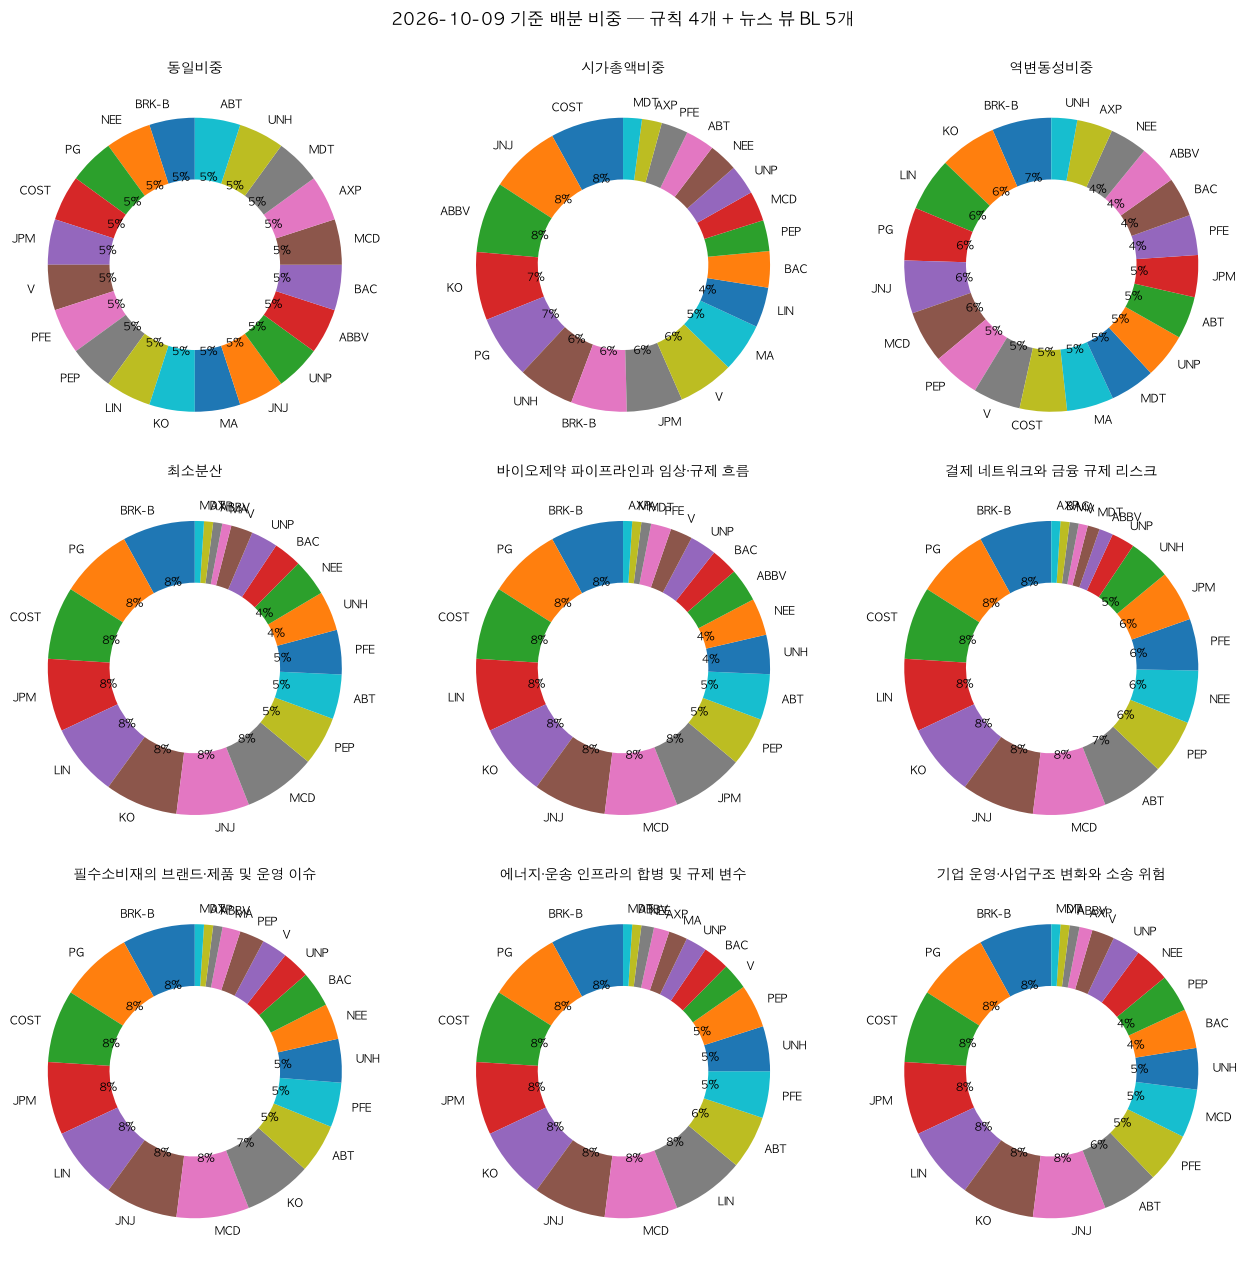

,비중,USD,원화
티커,,,
BRK-B,8.0%,"5,970.06","8,000,000"
PG,8.0%,"5,970.06","8,000,000"
COST,8.0%,"5,970.06","8,000,000"
LIN,8.0%,"5,970.06","8,000,000"
KO,8.0%,"5,970.06","8,000,000"
JNJ,8.0%,"5,970.06","8,000,000"
MCD,8.0%,"5,970.06","8,000,000"
JPM,7.9%,"5,914.69","7,925,800"
PEP,5.4%,"4,011.88","5,376,000"


In [14]:
F = R["portfolio"].get("forward")
if not F:
    print("현재 구성 결과 없음")
else:
    nw = F.get("news_window"); print(f"기준일 {F['as_of']} · 뉴스 창 {nw['window'][0]}~{nw['window'][1]} · 기사 {nw['n_articles']}건 · 뉴스 있는 종목 {nw['n_tickers_with_news']} · δ={F['market_model']['delta']} ({F['market_model']['delta_source']})" if nw else f"기준일 {F['as_of']}")
    sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0][:120], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                        "근거 수": len({i for v in p["views_applied"] for i in v.get("evidence_ids", [])}), "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in F["portfolios"]])
    display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
    ports = F["templates"] + F["portfolios"]
    cols = 3; rows_ = -(-len(ports) // cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(13, 4.2 * rows_))
    for ax, p in zip(axes.flat, ports):
        items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
        ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
        ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=10)
    for ax in list(axes.flat)[len(ports):]: ax.axis("off")
    plt.suptitle(f"{F['as_of']} 기준 배분 비중 — 규칙 4개 + 뉴스 뷰 BL {len(F['portfolios'])}개", y=1.0); plt.tight_layout(); plt.show()
    chosen = F["portfolios"][0] if F["portfolios"] else F["templates"][0]
    display(pd.DataFrame(chosen["allocation"]).rename(columns={"ticker": "티커", "weight": "비중", "usd": "USD", "krw": "원화"}).set_index("티커").style.format({"비중": "{:.1%}", "USD": "{:,.2f}", "원화": "{:,.0f}"}).set_caption(f"배분 금액 — {chosen['name_ko']} (투자금 {F['capital']['initial_amount_usd']:,.0f} USD)"))

## 7. 비용·조건·경고

In [15]:
u = R["llm_usage"]
if u.get("available"):
    display(pd.DataFrame(u["by_stage"]).T.style.format({"cost_usd": "{:.4f}"}).set_caption(f"분석 모델 호출 (누적, {u['model']}) — 합계 {u['total_cost_usd']:.4f} USD"))
display(pd.DataFrame(R["sources"])[["name", "what"]].rename(columns={"name": "출처", "what": "사용한 내용"}).set_index("출처"))
print("파라미터:", json.dumps(R["parameters"], ensure_ascii=False)[:600])
pd.DataFrame(R["warnings"]).rename(columns={"stage": "단계", "message": "경고"})

,calls,prompt_tokens,completion_tokens,cost_usd
02_intent,1.000000,6527.000000,2272.000000,0.0023
04_classify,3.000000,6594.000000,12932.000000,0.0079
09_views,1.000000,2396.000000,4073.000000,0.0026
09n_forward,1.000000,10760.000000,4879.000000,0.0049


,사용한 내용
출처,
팀 데이터베이스 price_daily,"일별 주가·수정주가·거래량 (여러 소스의 합의값 CONSENSUS 우선, 1종목·1일 1행)"
팀 데이터베이스 financials (SEC EDGAR),발행주식수 (시가총액 필터·시가총액 비중)
팀 데이터베이스 fx_daily,원/달러 환율 USDKRW (투자금 환산 기준일 종가)
Yahoo Finance (yfinance) 캐시 사본,비교지수 ETF (SPY·QQQ·XLV) — 팀 DB 미보유로 캐시 사본 사용
팀 데이터베이스 news,"종목 뉴스 헤드라인 (GOOGLE_RSS·NEWSAPI·NAVER_NEWS), 구성일 직전 14일 창"
Wikipedia,S&P 500 · NASDAQ-100 구성 종목과 GICS 세부산업
Wikipedia GICS,GICS 11 섹터 / 25 산업그룹 / 74 산업 / 163 세부산업 분류표
MyFinSight 파이프라인 계산,후보 검색·정량 스크린·비중 계산·Black-Litterman·백테스트(bt)·검증 규칙
분석 모델 (gpt-6-luna),"의도 해석, 테마 분류, 시나리오 뷰(정적 뷰는 뉴스 미연결, walk-forward·현재 구성은 DB 뉴스 근거), 리포트 서술"


파라미터: {"portfolio": {"LOOKBACK_DAYS": 756, "SHRINKAGE": "ledoit_wolf", "TAU": 0.05, "RISK_AVERSION": {"conservative": 4.0, "moderate": 2.5, "aggressive": 1.5}, "OMEGA_METHOD": "he_litterman_confidence", "CONFIDENCE_FLOOR": 0.1, "ABS_RETURN_RANGE": [-0.5, 1.0], "REL_RETURN_RANGE": [0.0, 0.5], "TEMPLATES": ["equal_weight", "market_cap", "inverse_volatility", "min_variance"]}, "backtest": {"COMMISSION_BPS": 5, "INTEGER_POSITIONS": false, "RISK_FREE_RATE": 0.04, "TRADING_DAYS": 252, "DRIFT_TOLERANCE": 0.25, "CHECKPOINT_FREQ": "rebalance", "VOL_BANDS": {"low": 0.15, "medium": 0.3, "high": 9.99}}, "llm": 


,단계,경고
0,03,candidate cap 120 applied
1,07,"capital re-converted at 2020-01-02 FX 1153.97: 86,657 USD vs request-date 74..."
2,12,no portfolio passed the hard rules (fail counts by rule: {'R1': 14}); recomm...
3,data,"DB 동기화(2026-10-10T11:21:13): DB price_daily에 없는 유니버스 종목 3개: SKYD, TWLO, VYLR..."
4,data,DB 동기화(2026-10-10T11:21:13): 발행주식수가 DB(SEC_EDGAR)에 없는 종목 44개는 yfinance 캐시 값을 사용
5,data,DB 동기화(2026-10-10T11:21:13): 비교지수(SPY·QQQ·XLV 등)는 팀 DB에 없어 yfinance 캐시 사본을 사...
